In [1]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd

bank = fetch_ucirepo(id=222)
df = pd.concat([bank.data.features, bank.data.targets], axis=1)

print(df.shape)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [2]:
!wget -O bank.zip "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
!unzip -o bank.zip
!unzip -o bank.zip -d bank_data
!ls

--2026-10-12 05:51:04--  https://archive.ics.uci.edu/static/public/222/bank+marketing.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘bank.zip’

bank.zip                [ <=>                ] 999.85K  5.82MB/s    in 0.2s    

2026-10-12 05:51:05 (5.82 MB/s) - ‘bank.zip’ saved [1023843]

Archive:  bank.zip
 extracting: bank.zip                
 extracting: bank-additional.zip     
Archive:  bank.zip
  inflating: bank_data/bank-full.csv  
  inflating: bank_data/bank-names.txt  
  inflating: bank_data/bank.csv      
bank-additional.zip  bank_data	bank.zip  sample_data


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [4]:
df.shape


(45211, 17)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [6]:
df.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [7]:
df.isnull().sum()



,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["y"].value_counts()
df["y"].value_counts(normalize=True) * 100

,proportion
y,
no,88.30152
yes,11.69848


In [10]:
df_clean = df.copy()

In [11]:
cols = ["job", "education", "contact", "poutcome"]

# Count missing (NaN) AND the literal word "unknown"
for c in cols:
    n_nan = df_clean[c].isnull().sum()
    n_unk = (df_clean[c] == "unknown").sum()
    print(c, "| NaN:", n_nan, "| 'unknown':", n_unk)

job | NaN: 288 | 'unknown': 0
education | NaN: 1857 | 'unknown': 0
contact | NaN: 13020 | 'unknown': 0
poutcome | NaN: 36959 | 'unknown': 0


In [12]:
# Make everything consistent: turn NaN into "unknown"
for c in cols:
    df_clean[c] = df_clean[c].fillna("unknown")

# Check how big each "unknown" group is (in %)
for c in cols:
    print(c, round((df_clean[c] == "unknown").mean() * 100, 1), "%")

job 0.6 %
education 4.1 %
contact 28.8 %
poutcome 81.7 %


In [13]:
print("Duplicates:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()

Duplicates: 0


In [14]:
df_clean["y"] = df_clean["y"].map({"yes": 1, "no": 0})
df_clean["y"].value_counts()

,count
y,
0,39922
1,5289


In [15]:
print((df_clean["pdays"] == -1).mean() * 100, "% were never contacted before")

df_clean["previously_contacted"] = (df_clean["pdays"] != -1).astype(int)

81.73674548229414 % were never contacted before


In [16]:
bins = [0, 24, 34, 44, 54, 64, 120]
labels = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
df_clean["age_group"] = pd.cut(df_clean["age"], bins=bins, labels=labels)

df_clean["age_group"].value_counts().sort_index()

,count
age_group,
<25,809
25-34,14204
35-44,14534
45-54,9958
55-64,4896
65+,810


In [17]:
month_map = {"jan":1,"feb":2,"mar":3,"apr":4,"may":5,"jun":6,
             "jul":7,"aug":8,"sep":9,"oct":10,"nov":11,"dec":12}
df_clean["month_num"] = df_clean["month"].str.lower().map(month_map)

df_clean["month_num"].isnull().sum()   # should be 0

np.int64(0)

In [18]:
# IQR method on balance
Q1 = df_clean["balance"].quantile(0.25)
Q3 = df_clean["balance"].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers = df_clean[(df_clean["balance"] < lower) | (df_clean["balance"] > upper)]
print("Outliers:", len(outliers), "=", round(len(outliers) / len(df_clean) * 100, 1), "%")
print("Negative balances:", (df_clean["balance"] < 0).sum())

Outliers: 4729 = 10.5 %
Negative balances: 3766


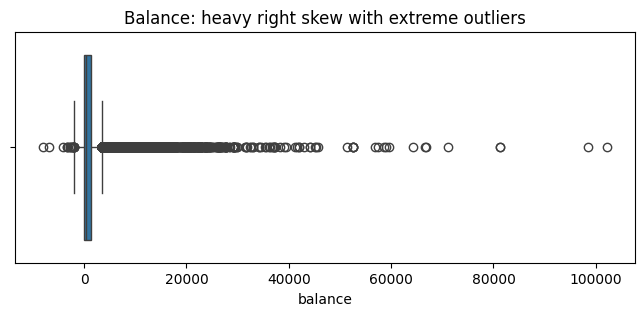

In [19]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df_clean["balance"])
plt.title("Balance: heavy right skew with extreme outliers")
plt.show()

In [20]:
print("Outliers:", len(outliers), "=", round(len(outliers) / len(df_clean) * 100, 1), "%")
print("Negative balances:", (df_clean["balance"] < 0).sum())

Outliers: 4729 = 10.5 %
Negative balances: 3766


EDA and Charts

In [21]:
print(df_clean.shape)
print(df_clean["y"].unique())   # should show [0 1]
print(df_clean[["age_group", "month_num", "previously_contacted"]].isnull().sum())   # all 0

(45211, 20)
[0 1]
age_group               0
month_num               0
previously_contacted    0
dtype: int64


In [22]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

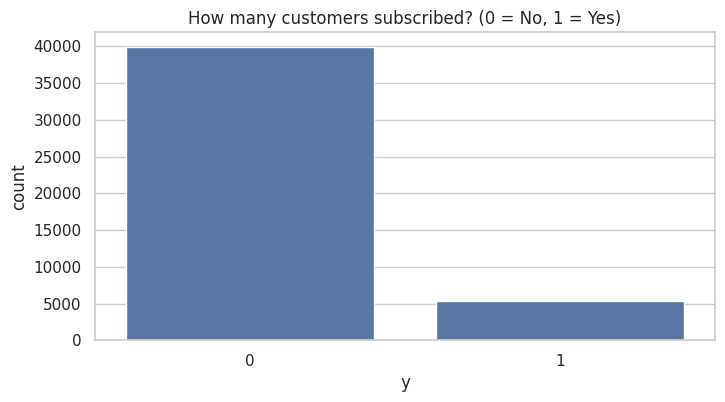

11.7 % subscribed


In [23]:
sns.countplot(x="y", data=df_clean)
plt.title("How many customers subscribed? (0 = No, 1 = Yes)")
plt.show()
print(round(df_clean["y"].mean() * 100, 1), "% subscribed")

Contact type: Cellular is the main channel (about 29,000 customers, roughly two-thirds of the data), followed by "unknown" (about 13,000, or 28.8%) and telephone (about 2,800). Meaning: the bank relied mostly on mobile calls. Limitation: since nearly 3 in 10 customers have an unknown contact type, any comparison of communication methods (Q8) should be treated carefully.

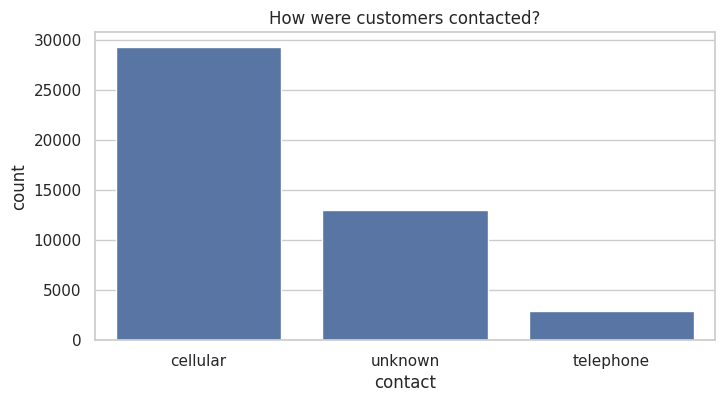

In [24]:
sns.countplot(x="contact", data=df_clean, order=df_clean["contact"].value_counts().index)
plt.title("How were customers contacted?")
plt.show()

Age distribution: Customers are concentrated between about 28 and 58 years old, peaking around 32-33. The distribution is right-skewed, with very few customers under 25 or over 65. Meaning: the bank's campaign mainly targeted working-age adults. Link to Q2: the high subscription rates for under-25s (25.6%) and 65+ (42.1%) come from small groups, so they should be treated as promising signals rather than firm conclusions. Recommendation: test targeted campaigns on these segments before scaling up.

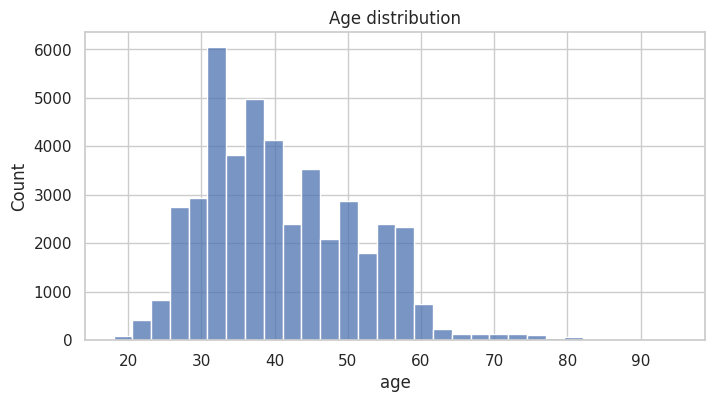

In [25]:
sns.histplot(df_clean["age"], bins=30)
plt.title("Age distribution")
plt.show()

Balance distribution (log scale): Among customers with positive balances, values range from about 1 to over 100,000 euros, with most clustered between roughly 300 and 1,000 euros. On a log scale the distribution is approximately bell-shaped, confirming a heavy right skew on the raw scale. Meaning: a few very wealthy customers would pull the average far above what a typical customer holds, so the median is a better summary. Note: this chart excludes the 3,766 customers with negative balances, which were analysed separately.

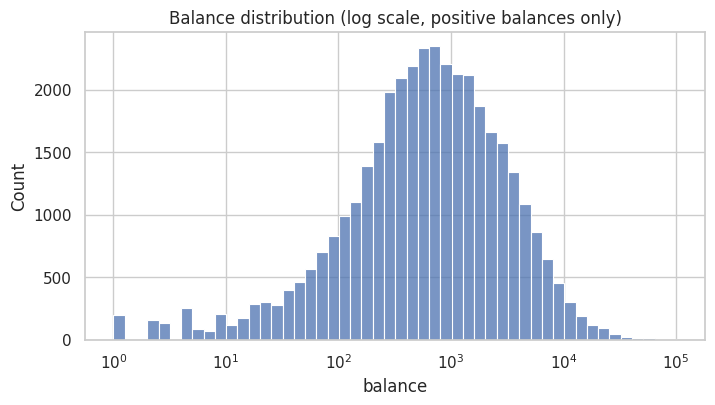

In [26]:
pos = df_clean[df_clean["balance"] > 0]
sns.histplot(pos["balance"], bins=50, log_scale=True)
plt.title("Balance distribution (log scale, positive balances only)")
plt.show()

Campaign contacts: Most customers were contacted only once (about 17,500) or twice (about 12,500) during this campaign. The distribution is strongly right-skewed, with a small group contacted many more times (the chart is limited to 20 contacts for readability). Meaning: the bank mostly made one or two attempts, but a minority were contacted repeatedly. Link to Q7: the next step is to check whether those repeated contacts led to more subscriptions or just diminishing returns.

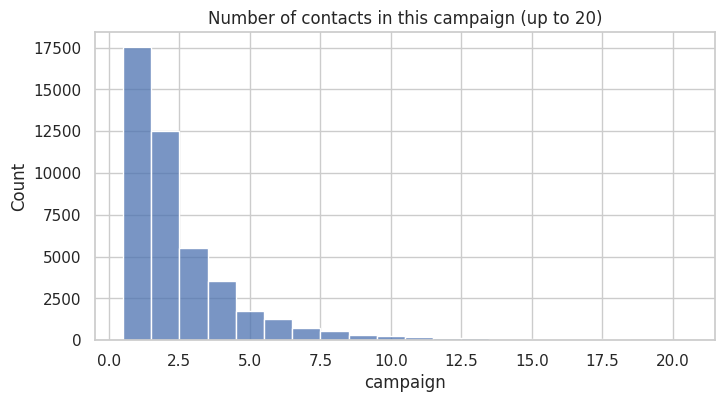

In [27]:
sns.histplot(df_clean[df_clean["campaign"] <= 20]["campaign"], discrete=True)
plt.title("Number of contacts in this campaign (up to 20)")
plt.show()

In [28]:
def rate_plot(col, sort=True, rotate=0):
    rate = df_clean.groupby(col, observed=True)["y"].mean() * 100
    if sort:
        rate = rate.sort_values(ascending=False)
    plt.figure(figsize=(9, 4))
    sns.barplot(x=rate.index.astype(str), y=rate.values)
    plt.axhline(df_clean["y"].mean() * 100, color="red", linestyle="--", label="Overall average")
    plt.ylabel("Subscription rate (%)")
    plt.title(f"Subscription rate by {col}")
    plt.xticks(rotation=rotate)
    plt.legend()
    plt.show()
    print(rate.round(1))

Q3: Job type clearly matters. Students (28.7%) and retired customers (22.8%) lead, while blue-collar workers (about 7%) are lowest. This agrees with the age pattern, since students are young and retirees are old. Recommendation: focus on students and retirees, and review whether calling blue-collar customers is worth the cost.

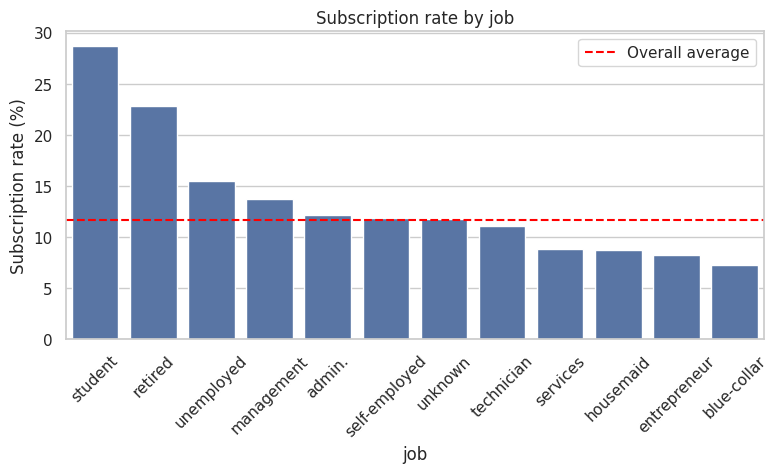

job
student          28.7
retired          22.8
unemployed       15.5
management       13.8
admin.           12.2
self-employed    11.8
unknown          11.8
technician       11.1
services          8.9
housemaid         8.8
entrepreneur      8.3
blue-collar       7.3
Name: y, dtype: float64


In [29]:
rate_plot("job", rotate=45)                 # Q3

Q4 (education): Education level influences subscription. Tertiary-educated customers subscribe at 15.0%, secondary at 10.6% and primary at 8.6%, so the rate rises with education. The "unknown" group (13.6%) is small, so it is not interpreted. Meaning: the effect is moderate, weaker than job or age. Recommendation: prioritise tertiary-educated customers, ideally combined with high-converting groups such as students and retirees. Caution: education may overlap with job type (e.g. management roles tend to have higher education), so it may not act independently.

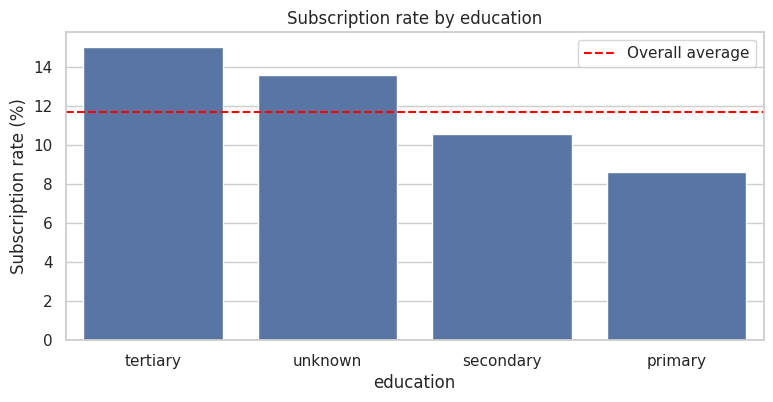

education
tertiary     15.0
unknown      13.6
secondary    10.6
primary       8.6
Name: y, dtype: float64


In [30]:
rate_plot("education")                      # Q4

Q5 (marital status): Marital status has a modest relationship with subscription. Single customers subscribe at 14.9%, divorced at 11.9% and married at 10.1%. Meaning: the differences are small compared to age or job. Caution: single status likely overlaps with younger age, which also shows higher subscription, so marital status may not act independently. Recommendation: treat marital status as a secondary targeting factor, behind age, job and previous campaign outcome.

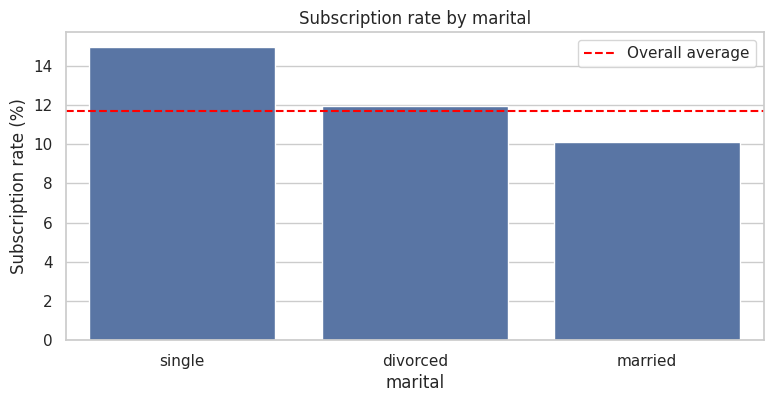

marital
single      14.9
divorced    11.9
married     10.1
Name: y, dtype: float64


In [31]:
rate_plot("marital")

Q2: Subscription follows a U-shape by age. Customers under 25 (25.6%) and 65+ (42.1%) subscribe at 2-3.6x the overall average of 11.7%, while ages 35-54 are lowest (about 9-10%). Recommendation: prioritise the youngest and oldest segments. Limitation: these groups have fewer customers than middle-aged groups.

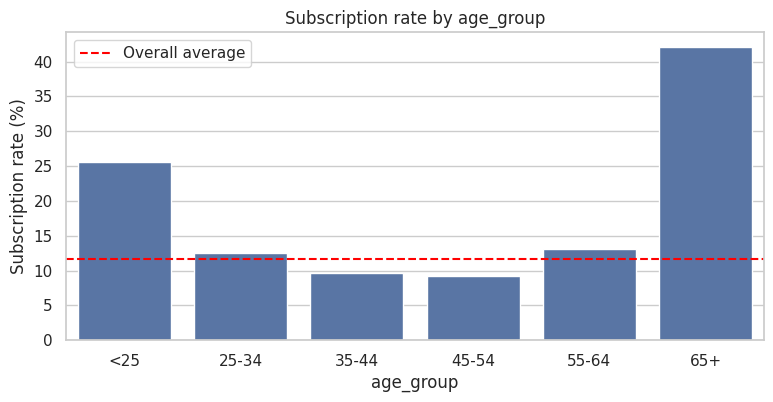

age_group
<25      25.6
25-34    12.5
35-44     9.7
45-54     9.3
55-64    13.1
65+      42.1
Name: y, dtype: float64


In [32]:
rate_plot("age_group", sort=False)

Q9 (previous campaign outcome): Previous campaign history is strongly related to the current outcome. Customers with a previous success subscribed at 64.7%, about 5.5x the overall average of 11.7%. Previous failures (12.6%) were close to average, and customers with no previous campaign (unknown, 9.2%) were lowest. Meaning: past behaviour is the best single predictor we have seen so far. Recommendation: re-contact previous successes first, and do not exclude previous failures, since they convert at about the average rate. Caution: the success group is small, so it is a high-value niche rather than a large source of new subscriptions.

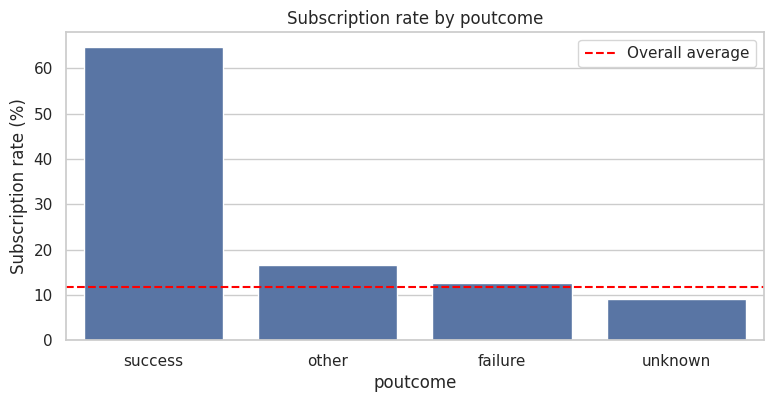

poutcome
success    64.7
other      16.7
failure    12.6
unknown     9.2
Name: y, dtype: float64


In [33]:
rate_plot("poutcome")

Q7 (campaign contacts): The number of contacts is negatively related to subscription. Customers contacted once subscribed at 14.6%, falling to 11.2% at 2-3 contacts, 8.6% at 4-5, 6.5% at 6-10 and 3.9% at 11 or more. Meaning: returns diminish after about three contacts. Recommendation: cap follow-up calls at around 3 per customer and redirect effort to new or high-converting segments. Caution: this shows an association, not causation. Customers who are hard to convert may simply be called more often.

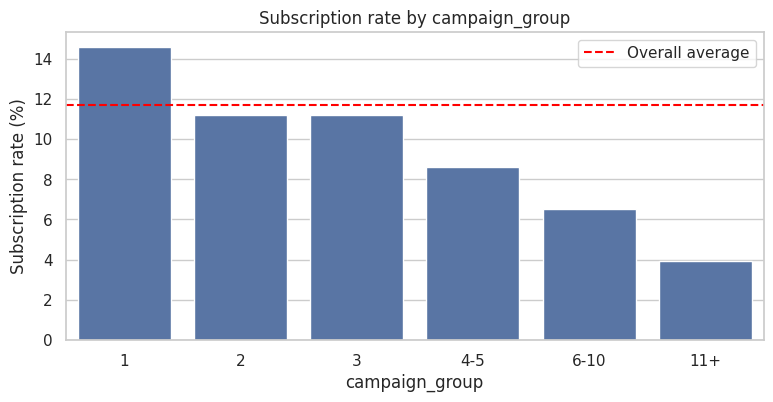

campaign_group
1       14.6
2       11.2
3       11.2
4-5      8.6
6-10     6.5
11+      3.9
Name: y, dtype: float64


In [34]:
# Q7: effect of number of contacts
df_clean["campaign_group"] = pd.cut(df_clean["campaign"], bins=[0, 1, 2, 3, 5, 10, 100],
                                    labels=["1", "2", "3", "4-5", "6-10", "11+"])
rate_plot("campaign_group", sort=False)

Q8 (communication method): Cellular contacts subscribed at 14.9% and telephone at 13.4%, both above the overall average of 11.7%. Contacts with an unknown method subscribed at only 4.1%. Meaning: among known channels, cellular is slightly more effective, though the gap is small. Recommendation: prefer cellular where possible, and improve how the contact method is recorded. Caution: the unknown group is 28.8% of customers and is unexplained, so its low rate may reflect timing or data-recording issues rather than the channel itself.

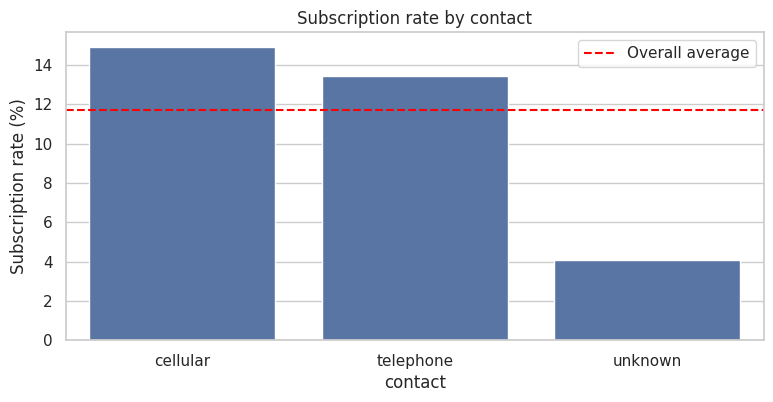

contact
cellular     14.9
telephone    13.4
unknown       4.1
Name: y, dtype: float64


In [35]:
rate_plot("contact")                        # Q8

Q6 (balance): Customers who subscribed have a higher median balance (733 euros) than those who did not (417 euros). Meaning: balance is associated with subscription, but the distributions overlap heavily, so balance alone is a modest indicator and cannot reliably separate the two groups. Recommendation: use balance as a secondary targeting signal alongside stronger factors like age, job and previous campaign outcome. Note: medians are used because balance is heavily right-skewed, and outlier dots were hidden in the plot for readability only (no data was removed).

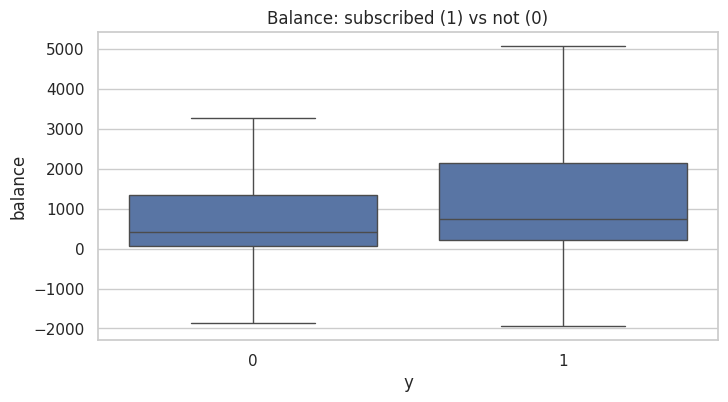

y
0    417.0
1    733.0
Name: balance, dtype: float64


In [36]:
sns.boxplot(x="y", y="balance", data=df_clean, showfliers=False)
plt.title("Balance: subscribed (1) vs not (0)")
plt.show()
print(df_clean.groupby("y")["balance"].median())

Duration by subscription: Customers who subscribed had much longer calls (median about 7 minutes) than those who did not (median under 3 minutes), with little overlap between the groups. Meaning: call length is strongly associated with the outcome, but this is most likely a result of customer interest rather than a cause. Important: duration is only known after the call, so it cannot be used to decide whom to contact. It is excluded from the predictive model to avoid data leakage. Recommendation: train call staff to keep engaged customers talking, but do not use duration for targeting.

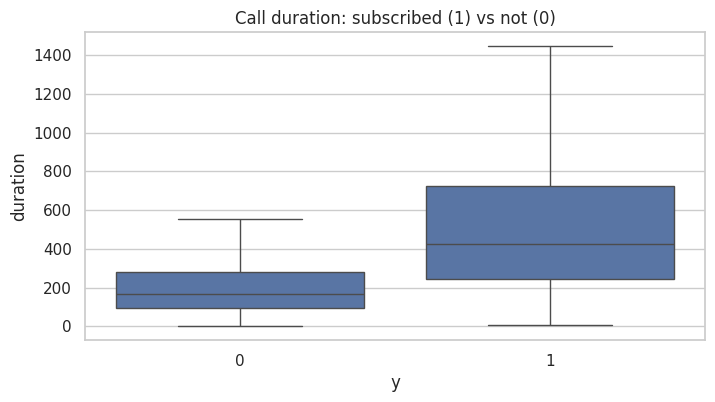

In [37]:
sns.boxplot(x="y", y="duration", data=df_clean, showfliers=False)
plt.title("Call duration: subscribed (1) vs not (0)")
plt.show()

Campaign by subscription: The typical number of contacts is the same for subscribers and non-subscribers (median 2, middle 50% between 1 and 3). Meaning: for most customers, number of contacts does not separate the two groups. The effect seen in Q7 comes from a minority contacted many times, whose subscription rate is much lower; these customers are hidden here because outlier points are not displayed. Note: outliers were hidden for readability only, with no data removed. Recommendation: focus on limiting excessive follow-ups (beyond about 3 calls) rather than the typical 1-3 call range.

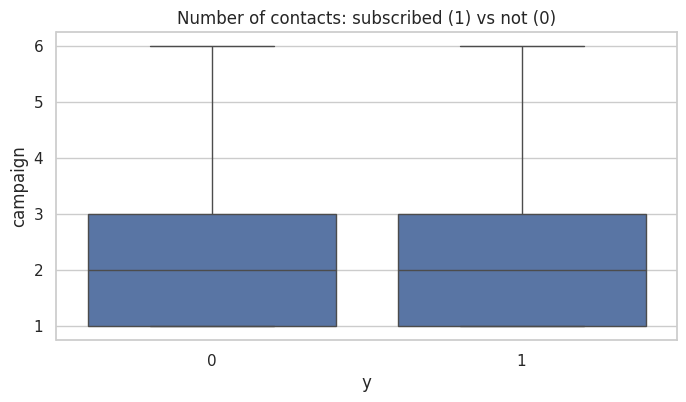

In [38]:
sns.boxplot(x="y", y="campaign", data=df_clean, showfliers=False)
plt.title("Number of contacts: subscribed (1) vs not (0)")
plt.show()

Age vs balance (scatter): There is no clear relationship between age and balance; customers of all ages hold mostly between 0 and 5,000 euros. Subscribers (orange) are a minority at every age and are not clearly separated from non-subscribers by these two variables alone. They appear slightly more often among the oldest customers. Meaning: age and balance together do not explain subscription well, supporting the Q6 finding that balance is only a modest indicator. Note: a random sample of 5,000 customers is shown, and the y-axis is limited to -2,000 to 20,000 for readability (no data removed).

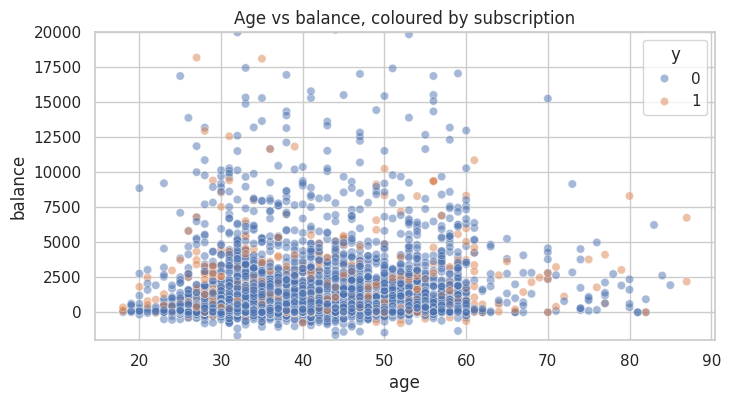

In [39]:
s = df_clean.sample(5000, random_state=42)

sns.scatterplot(x="age", y="balance", hue="y", data=s, alpha=0.5)
plt.ylim(-2000, 20000)
plt.title("Age vs balance, coloured by subscription")
plt.show()

Contacts vs call duration (scatter): Customers contacted many times tend to have short calls, while long calls (over about 1,000 seconds) occur almost only among customers with fewer than about 10 contacts. Subscribers (orange) are concentrated at longer durations and lower contact counts, and are rare beyond about 10 contacts. Meaning: repeated contact does not produce longer or more productive conversations; engagement is highest early. This supports the Q7 finding of diminishing returns after about 3 contacts. Note: a random sample of 5,000 customers is shown, limited to 30 or fewer contacts. Caution: duration is only known after a call, so it is used here for understanding only, not for prediction.

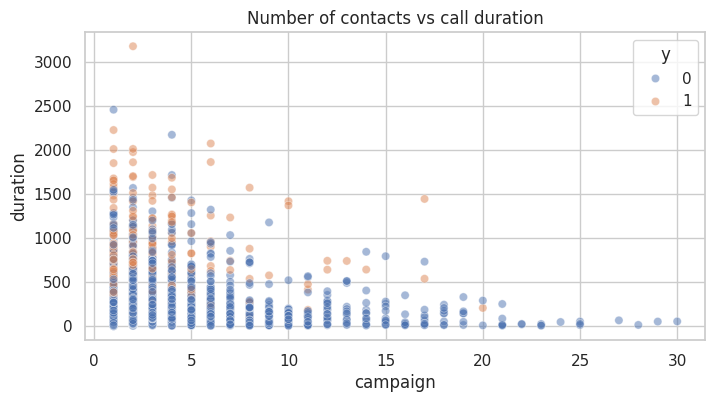

In [40]:
s2 = s[s["campaign"] <= 30]
sns.scatterplot(x="campaign", y="duration", hue="y", data=s2, alpha=0.5)
plt.title("Number of contacts vs call duration")
plt.show()

Correlation heatmap: Correlations between numeric variables and subscription are weak overall. Call duration is the strongest (0.39), followed by previously_contacted (0.17), pdays (0.10), previous (0.09) and campaign (-0.07). Age (0.03) and balance (0.05) are almost uncorrelated with subscription. Meaning: no single numeric variable predicts subscription well; categorical factors such as job, previous outcome and month carry more information. Caution: correlation captures only linear relationships, so it misses non-linear patterns like the U-shape in age (Q2). Note: pdays and previously_contacted are highly correlated (0.87) because one was derived from the other. Correlation does not imply causation.

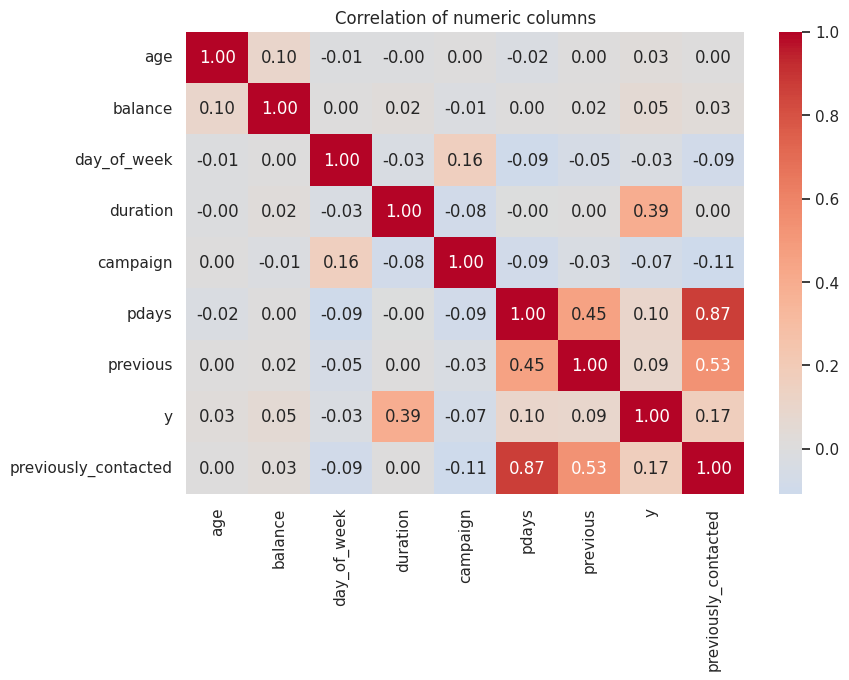

In [41]:
corr = df_clean.select_dtypes(include="number").drop(columns=["month_num"]).corr()
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric columns")
plt.show()

Monthly pattern: Call volume and subscription rate move in opposite directions. May had by far the most calls (about 13,700, roughly 30% of the total) but a low subscription rate (about 7%), while March (52.0%), September (about 46%), October (about 44%) and December (about 47%) had very few calls but very high rates. Meaning: the bank concentrated effort in its lowest-yield month. Recommendation: test shifting call volume towards the high-converting months, and review how customers were selected in those months. Caution: the high-rate months have small samples (a few hundred calls) and may reflect who was called rather than the month itself. The data has no year, so this is a seasonal pattern, not a true time series. Replace the approximate values with your printed numbers.

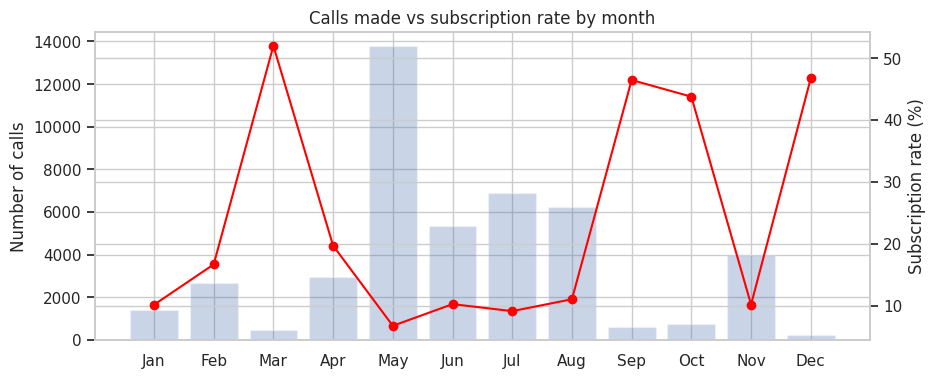

month_num
1     10.1
2     16.6
3     52.0
4     19.7
5      6.7
6     10.2
7      9.1
8     11.0
9     46.5
10    43.8
11    10.2
12    46.7
Name: rate, dtype: float64


In [42]:
monthly = df_clean.groupby("month_num")["y"].agg(["mean", "count"])
monthly["rate"] = monthly["mean"] * 100
names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(monthly.index, monthly["count"], alpha=0.3)
ax1.set_ylabel("Number of calls")
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(names)
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["rate"], color="red", marker="o")
ax2.set_ylabel("Subscription rate (%)")
plt.title("Calls made vs subscription rate by month")
plt.show()
print(monthly["rate"].round(1))

Q10 (segments, job × education): Students (26-36%) and retired customers (21-28%) subscribe at roughly 2-3x the overall average of 11.7% at every education level, so job or life stage matters more than education for them. For most other jobs, tertiary education is associated with a clear rise in subscription (e.g. blue-collar from 6% to 16%, self-employed from 4% to 16%), while entrepreneurs stay low (7-10%) regardless of education. Recommendation: prioritise students, retirees and tertiary-educated professionals, and reduce effort on low-converting segments such as primary-educated blue-collar and self-employed customers. Limitation: some cells (for example student × primary) contain few customers, so extreme values may be unreliable.

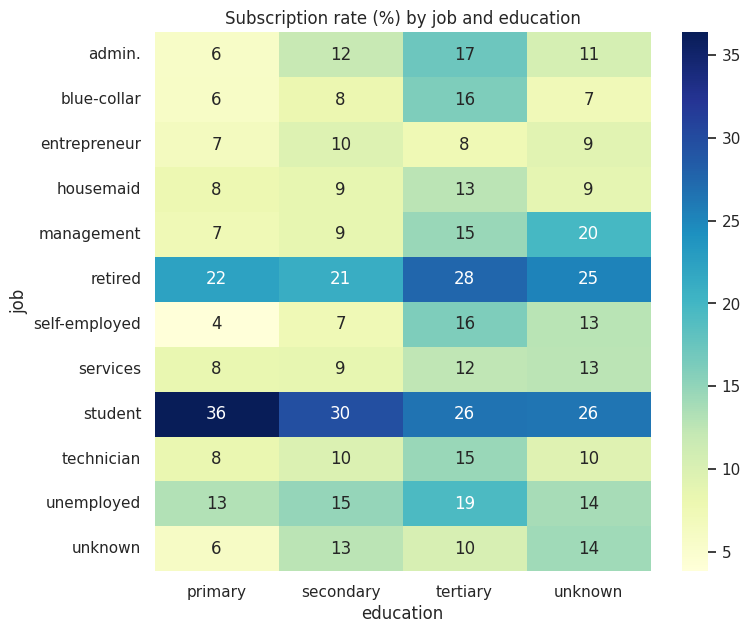

In [43]:
pivot = df_clean.pivot_table(values="y", index="job", columns="education", aggfunc="mean") * 100
plt.figure(figsize=(8, 7))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Subscription rate (%) by job and education")
plt.show()

Step 1: Features and target

In [44]:
X = df_clean.drop(columns=["y", "duration", "month_num", "campaign_group", "age_group"])
y = df_clean["y"]
print(X.shape)

(45211, 16)


Step 2: Text ni numbers ga marchadam (One-hot encoding)

In [45]:
X = pd.get_dummies(X, drop_first=True)
print(X.shape)
X.head()

(45211, 42)


,age,balance,day_of_week,campaign,pdays,previous,previously_contacted,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,1,-1,0,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True
1,44,29,5,1,-1,0,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True
2,33,2,5,1,-1,0,0,False,True,False,...,False,False,False,True,False,False,False,False,False,True
3,47,1506,5,1,-1,0,0,True,False,False,...,False,False,False,True,False,False,False,False,False,True
4,33,1,5,1,-1,0,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True


Step 3: Train/Test split

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())   # rendu kuda ~0.117 undali

(36168, 42) (9043, 42)
0.11698186241981863 0.11699657193409267


Step 4: Scaling

In [47]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Step 5: Training Logistic Regression

In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model.fit(X_train_s, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

Step 6: Predict Test Data

In [49]:
y_pred = model.predict(X_test_s)

Step 7: Results


In [50]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=["No (0)", "Yes (1)"]))


Accuracy: 0.756

              precision    recall  f1-score   support

      No (0)       0.94      0.77      0.85      7985
     Yes (1)       0.27      0.62      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.79      9043



Model results (Logistic Regression, duration excluded): On the 9,043-customer test set, the model achieved accuracy 0.756, precision 0.27, recall 0.62 and F1 0.37 for the “yes” class. It correctly identified 659 of 1,058 actual subscribers, missed 399, and made 1,810 unnecessary predictions of “yes”. Meaning: the model finds about 62% of subscribers and, among customers it flags, 27% subscribe, about 2.3x the 11.7% baseline rate. Accuracy is lower than a model that always predicts “no” (about 88%), but that model finds no subscribers, so accuracy is misleading here. Data leakage: duration was excluded because it is only known after the call. Limitations: baseline model with default settings, one bank, 2008-2010 Portuguese data, and class_weight="balanced" deliberately trades precision for recall.

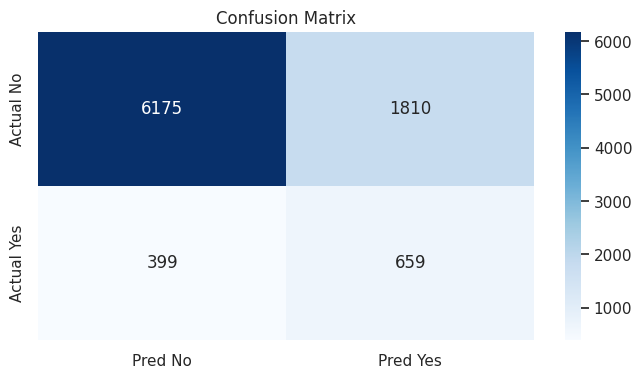

In [51]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred No", "Pred Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title("Confusion Matrix")
plt.show()

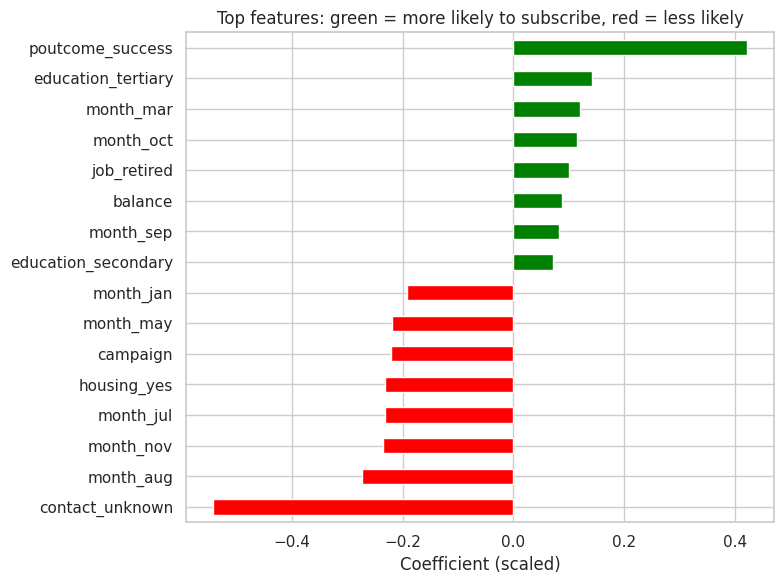

poutcome_success       0.42
education_tertiary     0.14
month_mar              0.12
month_oct              0.11
job_retired            0.10
balance                0.09
month_sep              0.08
education_secondary    0.07
dtype: float64
contact_unknown   -0.54
month_aug         -0.27
month_nov         -0.24
month_jul         -0.23
housing_yes       -0.23
campaign          -0.22
month_may         -0.22
month_jan         -0.19
dtype: float64


In [52]:
coef = pd.Series(model.coef_[0], index=X_train.columns).sort_values()

top = pd.concat([coef.head(8), coef.tail(8)])
plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=["red" if v < 0 else "green" for v in top])
plt.title("Top features: green = more likely to subscribe, red = less likely")
plt.xlabel("Coefficient (scaled)")
plt.tight_layout()
plt.show()

print(coef.sort_values(ascending=False).head(8).round(2))
print(coef.sort_values().head(8).round(2))

In [53]:
print(coef.sort_values().head(8).round(2))

contact_unknown   -0.54
month_aug         -0.27
month_nov         -0.24
month_jul         -0.23
housing_yes       -0.23
campaign          -0.22
month_may         -0.22
month_jan         -0.19
dtype: float64


# Conclusion

## What I found
- Only 11.7% of customers subscribed (imbalanced data).
- Subscription follows a U-shape by age: under-25 (25.6%) and 65+ (42.1%) are far above ages 35-54 (about 9-10%).
- Students (28.7%) and retired customers (22.8%) subscribe most; blue-collar is lowest (about 7%).
- Previous campaign success is the strongest signal (64.7%).
- Conversion falls with repeated contact: 14.6% at 1 contact, 3.9% at 11+.
- Unknown contact type converts at only 4.1% vs cellular 14.9%.
- A baseline Logistic Regression (duration excluded) found 62% of subscribers with 27% precision, about 2.3x better than random calling.

## Recommendations
1. Re-contact previous successes first.
2. Prioritise students, retirees and tertiary-educated customers.
3. Cap follow-up calls at about 3 per customer.
4. Prefer cellular contact and improve recording of contact method.
5. Test moving call volume from May to higher-yield months.

## Limitations
- One bank, 2008-2010 data.
- Association, not causation.
- Small samples in some segments and months.
- No year column, so monthly results are seasonal, not a true time series.
- Logistic Regression is linear and misses non-linear patterns like the age U-shape.

Title and questions

# Bank Marketing Campaign Analysis

**Objective:** Identify which customers and campaign practices are linked to term-deposit subscription, so future campaigns can be better targeted.

**Dataset:** UCI Bank Marketing (45,211 customers) - https://archive.ics.uci.edu/dataset/222/bank+marketing

## Key Questions
1. What percentage of customers subscribed?
2. Which age groups are more likely to subscribe?
3. Does job type influence subscription?
4. Does education level influence customer response?
5. Does marital status have any relationship with subscription?
6. Does account balance differ between customers who subscribed and those who did not?
7. How does the number of campaign contacts affect the outcome?
8. Which communication method appears most effective?
9. Does previous campaign history relate to the current outcome?
10. Which customer segments show interesting patterns?

Data Dictionary

## Data Dictionary

| Column | Meaning | Type |
|---|---|---|
| age | Customer age | Numeric |
| job | Type of job | Categorical |
| marital | Marital status | Categorical |
| education | Education level | Categorical |
| default | Has credit in default? | Categorical |
| balance | Average yearly balance (euros) | Numeric |
| housing | Has housing loan? | Categorical |
| loan | Has personal loan? | Categorical |
| contact | Contact method (cellular / telephone) | Categorical |
| day_of_week | Day of the month of last contact (1-31, despite the name) | Numeric |
| month | Month of last contact | Categorical |
| duration | Last call length in seconds (known only after the call) | Numeric |
| campaign | Number of contacts during this campaign | Numeric |
| pdays | Days since last contact in a previous campaign (-1 = never contacted) | Numeric |
| previous | Number of contacts before this campaign | Numeric |
| poutcome | Outcome of the previous campaign | Categorical |
| y | Subscribed to a term deposit? (target) | Target |

**Columns created during cleaning:** `previously_contacted` (0/1 flag from pdays), `age_group` (age bins), `month_num` (month as 1-12), `campaign_group` (contact-count bins).

Cleaning log

## Cleaning Log

| Issue found | Decision | Reason |
|---|---|---|
| Missing/"unknown" values: job 0.6%, education 4.1%, contact 28.8%, poutcome 81.7% | Converted blanks to "unknown" and kept as own category | Dropping rows would lose most of the data (poutcome); "unknown" can carry a pattern |
| Duplicate rows | Checked: 0 found | Avoid double counting |
| pdays = -1 (81.7% of customers) | Created `previously_contacted` flag | -1 is a code for "never contacted", not a real number; matches poutcome unknown (81.7%), so the columns agree |
| Target `y` stored as yes/no text | Converted to 1/0 | Mean of `y` equals the subscription rate; needed for ML |
| `age` continuous | Created `age_group` bins | Easier segment comparison |
| `balance`: 4,729 IQR outliers (10.5%), 3,766 negatives | Kept | Genuine customer behaviour; used medians and log scale for fair comparison |
| `duration` | Kept for EDA, excluded from the model | Known only after the call (data leakage) |
| `day_of_week` holds day of month | Documented in the data dictionary | Name is misleading |

**Feature importance note**

**Feature importance (Logistic Regression):** The strongest positive predictors of subscription were a previous campaign success (coefficient 0.42), tertiary education (0.14), contact in March (0.12), October (0.11) or September (0.08), retired status (0.10) and higher balance (0.09). The strongest negative predictors were unknown contact type (the largest negative bar), contact in July, August and November, having a housing loan, and a higher number of campaign contacts.

**Meaning:** the model's learned patterns agree with the EDA findings (Q3, Q4, Q7, Q8, Q9 and the monthly chart).

**Recommendation:** prioritise previous successes, retirees and tertiary-educated customers, limit repeat calls, and review low-yield months.

**Limitations:** coefficients show association, not causation. Logistic Regression is linear, so it cannot capture non-linear patterns such as the U-shape in age. Month effects come from small samples. `pdays` and `previously_contacted` are highly correlated (0.87), so their individual weights should not be over-interpreted.

Conclusion

# Conclusion

## What I found
- Only 11.7% of customers subscribed (imbalanced data).
- Subscription follows a U-shape by age: under-25 (25.6%) and 65+ (42.1%) are far above ages 35-54 (about 9-10%). These two groups have only about 810 customers each.
- Students (28.7%) and retired customers (22.8%) subscribe most; blue-collar is lowest (about 7%).
- Previous campaign success is the strongest signal (64.7%).
- Conversion falls with repeated contact: 14.6% at 1 contact, 3.9% at 11+.
- Unknown contact type converts at only 4.1% vs cellular 14.9%.
- A baseline Logistic Regression (duration excluded) found 62% of subscribers with 27% precision, about 2.3x better than random calling.

## Recommendations
1. Re-contact previous successes first.
2. Prioritise students, retirees and tertiary-educated customers.
3. Cap follow-up calls at about 3 per customer.
4. Prefer cellular contact and improve how contact method is recorded.
5. Test moving call volume away from May toward higher-yield months.

## Limitations
- One bank, 2008-2010 data.
- Findings show association, not causation.
- Small samples in some segments and months.
- No year column, so monthly results are seasonal, not a true time series.
- Logistic Regression is linear and misses non-linear patterns like the age U-shape.